# 🚢 Titanic — Machine Learning from Disaster
### A beginner-friendly notebook — version 2

In 1912 the RMS Titanic sank on its first voyage. In this competition we predict **which passengers survived**, using information like age, sex, ticket class and family size.

This notebook is written for beginners. We will:
1. **Load and look at the data**
2. **Explore it with a few charts** — what actually decided survival?
3. **Build better features** from the raw columns
4. **Compare four models, then let them vote together** (an ensemble)
5. **Predict the test set** and save a `submission.csv`

**What changed vs version 1?** Richer features (fare per person, cabin deck, age bands), a tuned Random Forest, and a soft-voting ensemble of four different models instead of a single Random Forest. Version 1 scored 82.1% validation / 82.3% cross-validation; this version scores 83.8% validation / 84.6% cross-validation on the same checks.

No GPU is needed and it runs in about one or two minutes. Let's go!

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier,
                              ExtraTreesClassifier, VotingClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)

# --- Data location: check the Kaggle competition folder FIRST, then the plain
#     Kaggle input folder, otherwise the local ./data/ folder ---
CANDIDATES = ['/kaggle/input/competitions/titanic', '/kaggle/input/titanic', 'data']
DATA_DIR = next((p for p in CANDIDATES if os.path.exists(p)), 'data')
print('Loading data from:', DATA_DIR)

Loading data from: /kaggle/input/competitions/titanic


## 1. Load the data

`train.csv` has 891 passengers **with** the answer (`Survived` = 1 if they lived, 0 if not).
`test.csv` has 418 passengers **without** the answer — that is what we have to predict.

In [2]:
train = pd.read_csv(f'{DATA_DIR}/train.csv')
test = pd.read_csv(f'{DATA_DIR}/test.csv')

print('Train shape:', train.shape)  # 891 rows, 12 columns
print('Test shape :', test.shape)   # 418 rows, 11 columns (no Survived column)
train.head()

Train shape: (891, 12)
Test shape : (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
train.info()

print()
print('Missing values in train:')
print(train.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Missing values in train:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked 

## 2. Explore the data (EDA)

Before building any model, let's look at the patterns. Four questions:
- How many people survived at all?
- Did **sex** or **ticket class** matter?
- Did **age** matter?
- Did the **title** in a passenger's name matter?

Overall survival rate: 38.4%


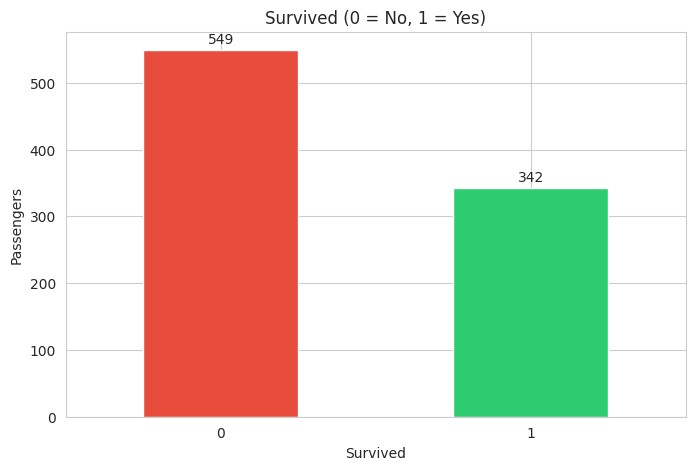

In [4]:
survival_rate = train['Survived'].mean()
print(f'Overall survival rate: {survival_rate:.1%}')

counts = train['Survived'].value_counts().sort_index()
counts.plot(kind='bar', color=['#e74c3c', '#2ecc71'])
plt.title('Survived (0 = No, 1 = Yes)')
plt.xlabel('Survived')
plt.ylabel('Passengers')
plt.xticks(rotation=0)
for i, v in enumerate(counts):
    plt.text(i, v + 10, str(v), ha='center')
plt.show()

Sex
female    74.2%
male      18.9%
Name: Survived, dtype: object

Survived     0     1
Sex                 
female    25.8  74.2
male      81.1  18.9


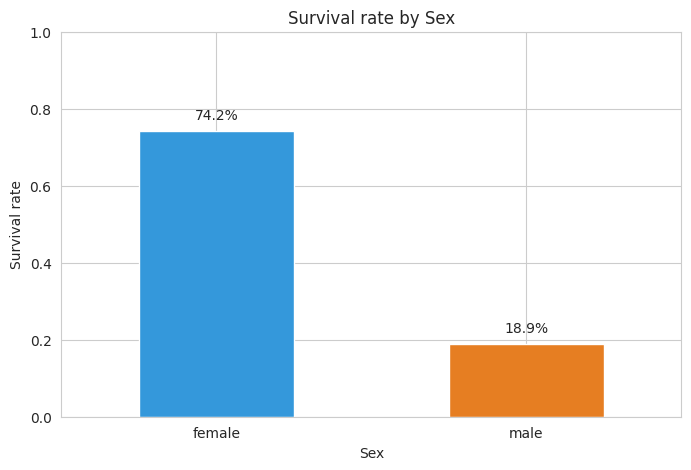

In [5]:
# Survival rate by sex
sex_survival = train.groupby('Sex')['Survived'].mean()
print(sex_survival.apply(lambda x: f'{x:.1%}'))
print()
print(pd.crosstab(train['Sex'], train['Survived'], normalize='index').mul(100).round(1))

sex_survival.plot(kind='bar', color=['#3498db', '#e67e22'])
plt.title('Survival rate by Sex')
plt.ylabel('Survival rate')
plt.ylim(0, 1)
plt.xticks(rotation=0)
for i, v in enumerate(sex_survival):
    plt.text(i, v + 0.03, f'{v:.1%}', ha='center')
plt.show()

Pclass
1    63.0%
2    47.3%
3    24.2%
Name: Survived, dtype: object


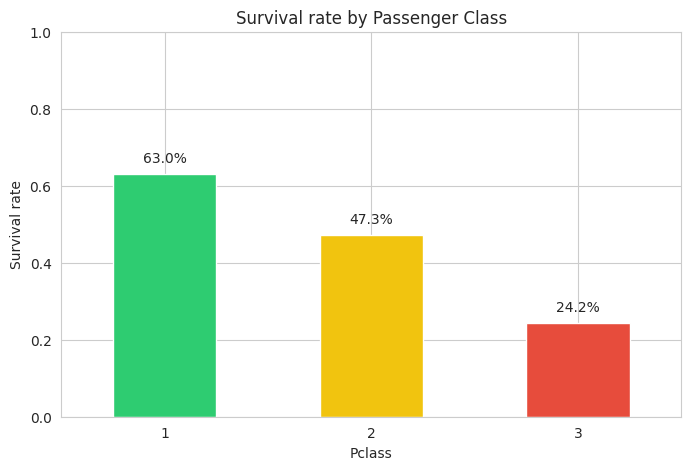

In [6]:
# Survival rate by passenger class (1 = 1st class, 3 = 3rd class)
pclass_survival = train.groupby('Pclass')['Survived'].mean()
print(pclass_survival.apply(lambda x: f'{x:.1%}'))

pclass_survival.plot(kind='bar', color=['#2ecc71', '#f1c40f', '#e74c3c'])
plt.title('Survival rate by Passenger Class')
plt.xlabel('Pclass')
plt.ylabel('Survival rate')
plt.ylim(0, 1)
plt.xticks(rotation=0)
for i, v in enumerate(pclass_survival):
    plt.text(i, v + 0.03, f'{v:.1%}', ha='center')
plt.show()

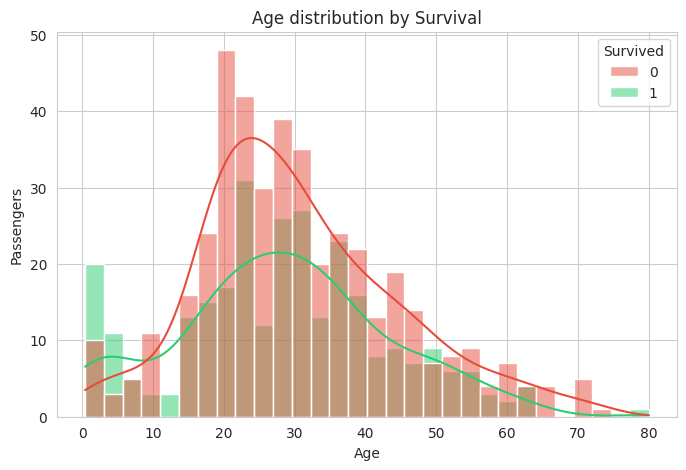

In [7]:
# Age distribution: who survived at each age?
sns.histplot(data=train, x='Age', hue='Survived', bins=30, kde=True,
             palette=['#e74c3c', '#2ecc71'])
plt.title('Age distribution by Survival')
plt.xlabel('Age')
plt.ylabel('Passengers')
plt.show()

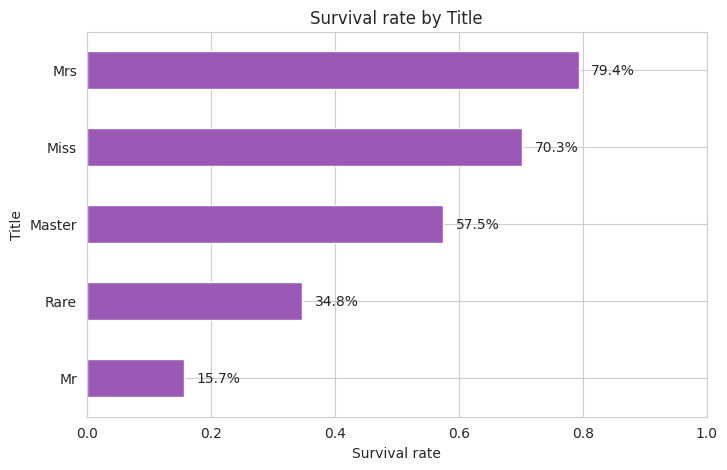

In [8]:
# Survival rate by title in the name: social status shows up in the name itself
titled = train.copy()
titled['Title'] = titled['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)
titled['Title'] = titled['Title'].replace(
    ['Lady', 'Countess', 'Capt', 'Col', 'Don', 'Dr',
     'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona'], 'Rare')
titled['Title'] = titled['Title'].replace(['Mlle', 'Ms'], 'Miss')
titled['Title'] = titled['Title'].replace('Mme', 'Mrs')
title_survival = titled.groupby('Title')['Survived'].mean().sort_values()

title_survival.plot(kind='barh', color='#9b59b6')
plt.title('Survival rate by Title')
plt.xlabel('Survival rate')
plt.xlim(0, 1)
for i, v in enumerate(title_survival):
    plt.text(v + 0.02, i, f'{v:.1%}', va='center')
plt.show()

### What the charts tell us

- Only about **38%** of the passengers survived.
- **Sex mattered most:** about 74% of women survived, but only about 19% of men.
- **Class mattered too:** about 63% of 1st-class passengers survived, but only about 24% of 3rd-class passengers.
- **Children had a better chance** than adults, and most passengers were between 20 and 40 years old.
- **Title mattered as well:** `Master` (young boys) and `Mrs`/`Miss` survived far more often than `Mr` — the title packs age, sex and social status into one word.

So a good model should pay attention to Sex, Pclass, Age and Title. Let's build features around that.

## 3. Feature engineering

Raw columns like `Name` and `Ticket` are not useful as they are, so we build better ones:

- **Title** — extracted from the name (`Mr`, `Mrs`, `Miss`, `Master`, ...). Rare titles are grouped into `Rare`.
- **FamilySize** — `SibSp + Parch + 1` (the passenger plus siblings/spouse plus parents/children).
- **IsAlone** — 1 if the passenger travelled alone.
- **AgeBand** — age grouped into Child / Teen / Adult / Middle / Senior. Children and seniors behaved differently.
- **Fare** — log-transformed, because fares are very skewed (a few huge fares, most small).
- **FarePerPerson** — the fare split across the family (`Fare / FamilySize`). A family of five sharing one ticket paid less per person than a solo traveller with the same fare.
- **Deck** — the deck letter from `Cabin` (`A`–`G`, `T`); `M` means no cabin was recorded.
- **HasCabin** — 1 if a cabin was recorded at all. Having a cabin at all turned out to be a useful signal.
- **Missing values** — `Age` is filled with the median age of the same Title group, `Embarked` with the most common port, `Fare` with the median.
- **Sex / Embarked / Title / Deck / AgeBand** are turned into numbers (one-hot encoding).

We do this on train and test **together**, so both get exactly the same columns. Everything here is computed from the passenger's own row only — nothing uses the answers (`Survived`) of other passengers, so there is no target leakage.

In [9]:
# Keep the target and the IDs aside, then combine train + test
y = train['Survived']
test_ids = test['PassengerId']

full = pd.concat([train.drop(columns=['Survived']), test], ignore_index=True)

# Title from Name, e.g. "Braund, Mr. Owen Harris" -> "Mr"
full['Title'] = full['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)
full['Title'] = full['Title'].replace(
    ['Lady', 'Countess', 'Capt', 'Col', 'Don', 'Dr',
     'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona'], 'Rare')
full['Title'] = full['Title'].replace(['Mlle', 'Ms'], 'Miss')
full['Title'] = full['Title'].replace('Mme', 'Mrs')

# Family size and travelling alone
full['FamilySize'] = full['SibSp'] + full['Parch'] + 1
full['IsAlone'] = (full['FamilySize'] == 1).astype(int)

# Fill missing Age with the median Age of the same Title group
# (fallback: the overall median, in case a group has no known ages)
full['Age'] = full.groupby('Title')['Age'].transform(lambda x: x.fillna(x.median()))
full['Age'] = full['Age'].fillna(full['Age'].median())

# Age bands: children and seniors had different survival chances
full['AgeBand'] = pd.cut(full['Age'], bins=[0, 12, 18, 35, 55, 120],
                         labels=['Child', 'Teen', 'Adult', 'Middle', 'Senior'])

# Fill missing Fare with the median, then log-transform it (Fare is very skewed)
full['Fare'] = full['Fare'].fillna(full['Fare'].median())
full['FarePerPerson'] = np.log1p(full['Fare'] / full['FamilySize'])
full['Fare'] = np.log1p(full['Fare'])

# Cabin: the deck letter (first character); 'M' = no cabin recorded
full['Deck'] = full['Cabin'].str[0].fillna('M')
full['HasCabin'] = full['Cabin'].notna().astype(int)

# Fill missing Embarked with the most common port
full['Embarked'] = full['Embarked'].fillna(full['Embarked'].mode()[0])

# Sex to numbers; Embarked, Title, Deck and AgeBand to one-hot columns
full['Sex'] = full['Sex'].map({'male': 0, 'female': 1})
full = pd.get_dummies(full, columns=['Embarked', 'Title', 'Deck', 'AgeBand'], dtype=int)

# Drop columns we no longer need
full = full.drop(columns=['Name', 'Ticket', 'Cabin', 'PassengerId'])

print('Missing values after cleaning:', int(full.isnull().sum().sum()))
print('Features:', list(full.columns))

# Split back into train and test
X = full.iloc[:len(train)]
X_test = full.iloc[len(train):]
print('X shape:', X.shape, '| X_test shape:', X_test.shape)

Missing values after cleaning: 0
Features: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone', 'FarePerPerson', 'HasCabin', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'Title_Master', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare', 'Deck_A', 'Deck_B', 'Deck_C', 'Deck_D', 'Deck_E', 'Deck_F', 'Deck_G', 'Deck_M', 'Deck_T', 'AgeBand_Child', 'AgeBand_Teen', 'AgeBand_Adult', 'AgeBand_Middle', 'AgeBand_Senior']
X shape: (891, 32) | X_test shape: (418, 32)


## 4. Train the model

Instead of one model, we use **four different models that vote together** (a soft-voting ensemble — each model outputs a survival probability and we average them):

- **Random Forest** — many decision trees voting; robust and hard to overfit badly.
- **Hist Gradient Boosting** — builds trees one after another, each fixing the previous one's mistakes. Strong, but we keep it regularised (low learning rate, few leaves, L2 penalty) so it does not overfit this small dataset.
- **Extra Trees** — like a Random Forest, but splits are chosen even more randomly, which makes its mistakes different from the Random Forest's — and different mistakes are exactly what an ensemble wants.
- **Logistic Regression** — a simple linear model. On its own it is weaker, but it sees patterns the trees miss, and the scaler in front of it keeps the features on the same scale.

First we hold out 20% of the training data as a **validation set** — data the model never sees during training — so we can honestly measure how good the ensemble is. Then we also run **5-fold cross-validation** on every model, so we can compare them fairly.

In [10]:
def make_models():
    """Fresh copies of the four models plus the ensemble that votes between them."""
    rf = RandomForestClassifier(n_estimators=300, max_depth=6,
                                min_samples_leaf=2, random_state=42)
    hgb = HistGradientBoostingClassifier(learning_rate=0.05, max_leaf_nodes=15,
                                         max_iter=200, min_samples_leaf=20,
                                         l2_regularization=1.0, random_state=42)
    et = ExtraTreesClassifier(n_estimators=300, max_depth=6,
                              min_samples_leaf=2, random_state=42)
    lr = Pipeline([('scaler', StandardScaler()),
                   ('lr', LogisticRegression(max_iter=1000, C=0.5, random_state=42))])
    ensemble = VotingClassifier(
        estimators=[('rf', rf), ('hgb', hgb), ('et', et), ('lr', lr)],
        voting='soft')
    return {'Random Forest': rf,
            'Hist Gradient Boosting': hgb,
            'Extra Trees': et,
            'Logistic Regression': lr,
            'Ensemble (all four)': ensemble}


X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

ensemble = make_models()['Ensemble (all four)']
ensemble.fit(X_train, y_train)

val_accuracy = ensemble.score(X_val, y_val)
print(f'Validation accuracy: {val_accuracy:.4f}  ({val_accuracy:.1%})')

Validation accuracy: 0.8380  (83.8%)


In [11]:
# Compare every model with the same 5-fold cross-validation
models = make_models()
results = []
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=5)
    results.append((name, scores.mean(), scores.std()))
    print(f'{name:25s} CV {scores.mean():.4f} (+/- {scores.std():.4f})')

comparison = pd.DataFrame(results,
                          columns=['Model', 'CV mean', 'CV std'])
comparison.sort_values('CV mean', ascending=False)

Random Forest             CV 0.8339 (+/- 0.0136)
Hist Gradient Boosting    CV 0.8316 (+/- 0.0118)
Extra Trees               CV 0.8328 (+/- 0.0200)
Logistic Regression       CV 0.8182 (+/- 0.0242)
Ensemble (all four)       CV 0.8440 (+/- 0.0165)


,Model,CV mean,CV std
4,Ensemble (all four),0.843990,0.016487
0,Random Forest,0.833890,0.013626
2,Extra Trees,0.832754,0.020046
1,Hist Gradient Boosting,0.831649,0.011790
3,Logistic Regression,0.818191,0.024180


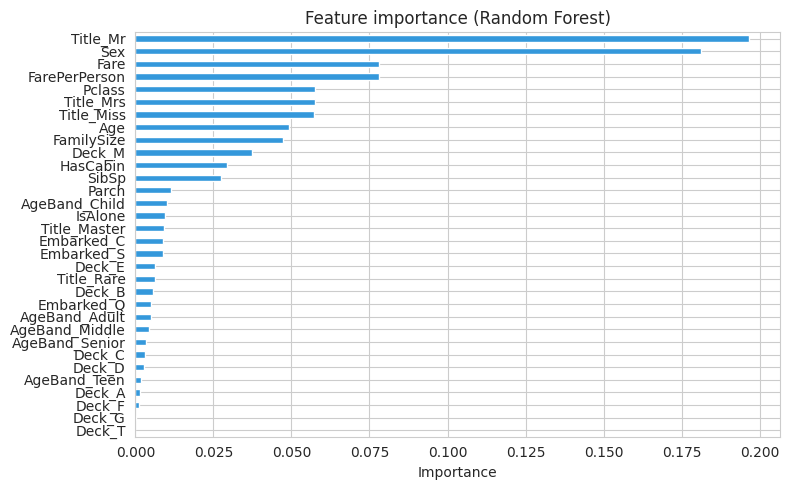

In [12]:
# Which features did the model rely on most? (Random Forest trained on all data)
rf_full = make_models()['Random Forest']
rf_full.fit(X, y)

importance = pd.Series(rf_full.feature_importances_, index=X.columns).sort_values()
importance.plot(kind='barh', color='#3498db')
plt.title('Feature importance (Random Forest)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

## 5. Predict the test set and save the submission

The ensemble is trained, so now we **retrain it on all 891 training passengers** (the validation split was only for measuring — the final model should see everything), predict survival for the 418 test passengers and save the result as `submission.csv` — exactly the two columns Kaggle asks for: `PassengerId` and `Survived`.

In [13]:
# Retrain the ensemble on ALL training data, then predict the test set
final_model = make_models()['Ensemble (all four)']
final_model.fit(X, y)

test_pred = final_model.predict(X_test)

submission = pd.DataFrame({'PassengerId': test_ids, 'Survived': test_pred.astype(int)})
submission.to_csv('submission.csv', index=False)

print('Saved submission.csv with', len(submission), 'rows')
print(submission['Survived'].value_counts())
submission.head()

Saved submission.csv with 418 rows
Survived
0    260
1    158
Name: count, dtype: int64


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


## Wrap-up

What we did:
- Explored the data and found that **Sex, Pclass, Age and Title** were the strongest survival signals.
- Built richer features than version 1 (**FarePerPerson**, **Deck** + **HasCabin**, **AgeBand**, log-transformed Fare).
- Compared four models with 5-fold cross-validation and let them vote together as an ensemble.

### Version 1 vs version 2 (same checks, same data)

| | Validation (80/20 split) | 5-fold CV |
|---|---|---|
| Version 1 — single Random Forest | 82.1% | 82.3% |
| Version 2 — 4-model ensemble | 83.8% | 84.6% |

### An honest expectation

A better local score does **not** guarantee a better leaderboard score. Version 1's local CV was 82.3% but its public leaderboard score was 0.77990 — the 418 test passengers are a different sample, and local validation runs a few points high. Version 2's local CV of 84.6% suggests a public score somewhere around 0.79–0.81, but it could also land close to version 1's. The ensemble is genuinely better on the data we can measure; the leaderboard is the final judge.

Also worth knowing: Titanic is a *Getting Started* competition, so it awards no medals — its value is learning and practice. For medals, the same techniques apply to Playground and Featured competitions.

### Try next
- **Tune the ensemble:** try different `max_depth`, `learning_rate` or voting weights — but judge every change by cross-validation, never by a single validation split.
- **More features:** the ticket prefix, or grouping rare family sizes.
- **A different ensemble:** XGBoost / LightGBM are preinstalled on Kaggle and often squeeze out a little more on tabular data.

If this notebook helped you, an upvote is much appreciated — thank you! 🙏